# Haar Face Detection: how good is the classic cascade, really?

**The question:** the Haar cascade is the "hello world" of computer vision: a few lines of OpenCV find faces in a webcam feed, and the demos look great on a clear, front-facing face. The legacy script here simply ran it with the tutorial defaults (`scaleFactor=1.3`, `minNeighbors=5`) and drew boxes. *But how many of the faces in everyday photographs does it actually find, can two settings fix that, how does it do against modern detectors, and what kind of faces does it miss?* We test on **500 photographs from WIDER FACE**, a benchmark with crowds, small faces, blur and odd poses, using hand-drawn ground truth.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the photographs and the faces in them
4. Hypotheses and why we chose each test
5. The detectors
6. H1: how many faces does the legacy setting find?
7. H2: can two settings fix it?
8. H3: how do modern detectors compare?
9. H4: which faces does it miss?
10. H5: what does it cost in time?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab CV/haar-face-eye-detection/haar_face_eye_detection.ipynb`, or *Run All* in any Jupyter. The photographs (a few hundred MB of the WIDER FACE validation split) and the small detector models download themselves on the first run; it takes about 10 minutes on a CPU. MediaPipe needs the system library `libgles2` (`sudo apt install libgles2` on Debian or Ubuntu).

## 1. 💡 The simple analogy

Imagine a **guard at a door who knows one trick:** "a face has a dark band across the eyes, a bright bridge of the nose and a dark mouth." He checks every window of the picture at every size against that pattern.

- At **full attention** (looking at many sizes, asking only a few cues to agree) he spots lots of faces but also calls shadows and wallpaper "faces".
- At the **tutorial setting** he is relaxed and strict: he skips most sizes and wants five cues to agree, so he rarely cries wolf, but he **misses most people**, especially those who are small, turned away, blurred or half hidden.
- A **modern detector** is a guard who has seen millions of faces in all kinds of situations instead of relying on one pattern.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of images and the match rule keeps the notebook reproducible and avoids "magic numbers". Two rules matter: images are shrunk so the longest side is **640 pixels** (the size of a webcam frame), and a detection counts as correct when its box overlaps a real face by an **intersection over union (IoU) of at least 0.5**.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import contextlib
import sys
import time
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from huggingface_hub.utils import logging as hub_logging
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint

hub_logging.set_verbosity_error()


DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
N_IMAGES = 500
MAX_SIDE = 640  # every image is shrunk so its longest side is this many pixels
MIN_FACE = 30  # faces smaller than this (in the shrunk image) are ignored, not scored
IOU_MATCH = 0.5
N_BOOTSTRAP = 2_000
MODEL_URLS = {
    "haarcascade_frontalface_default.xml": "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/"
    "haarcascade_frontalface_default.xml",
    "face_detection_yunet_2023mar.onnx": "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/"
    "face_detection_yunet_2023mar.onnx",
    "blaze_face_short_range.tflite": "https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/"
    "float16/1/blaze_face_short_range.tflite",
}
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the photographs and the faces in them

*What:* WIDER FACE has hand-drawn boxes for every face, plus labels for **blur, occlusion, pose and illumination**. We draw 500 random images from the 3,226 in the validation split, shrink them to 640 pixels, and score only faces at least **30 pixels tall**; smaller or invalid faces are "ignored" (finding them is neither rewarded nor punished). *Why:* a benchmark with known truth lets us count what a detector finds and misses, which a webcam demo can't.

> **Problems in the legacy script this replaces:** it drew boxes on whatever local images or webcam frames were at hand, so nothing was ever measured; it used the tutorial defaults without saying why (and its comment said `minNeighbors = 3` while the code used 5); and it needed model files that were never downloaded for you.

In [2]:
for name, url in MODEL_URLS.items():
    target = DATA_DIR / name
    if not target.exists():
        urllib.request.urlretrieve(url, target)

wider = load_dataset(
    "CUHK-CSE/wider_face",
    split="validation",
    revision="refs/convert/parquet",
    cache_dir=str(DATA_DIR / "hf"),
)


def prepare(example: dict) -> dict | None:
    """Shrinks an image and keeps the faces we will score.

    Faces marked invalid by the dataset, or smaller than ``MIN_FACE`` pixels after shrinking,
    are kept as "ignored" regions: finding them is neither rewarded nor punished.

    Args:
        example: One WIDER FACE record.

    Returns:
        The BGR image, the scored faces (with their attributes) and the ignored boxes; or None
        if the image has no scored face.
    """
    rgb = np.asarray(example["image"].convert("RGB"))
    scale = MAX_SIDE / max(rgb.shape[:2])
    image = cv2.cvtColor(
        cv2.resize(rgb, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA), cv2.COLOR_RGB2BGR
    )
    faces = example["faces"]
    boxes = np.array(faces["bbox"], np.float32).reshape(-1, 4) * scale
    scored, ignored = [], []
    for i, box in enumerate(boxes):
        small = min(box[2], box[3]) < MIN_FACE
        if faces["invalid"][i] or small:
            ignored.append(box)
        else:
            scored.append(
                {
                    "box": box,
                    "blur": faces["blur"][i],
                    "occlusion": faces["occlusion"][i],
                    "pose": faces["pose"][i],
                    "illumination": faces["illumination"][i],
                    "size": float(min(box[2], box[3])),
                }
            )
    return {"image": image, "scored": scored, "ignored": ignored} if scored else None


order = np.random.default_rng(SEED).permutation(len(wider))
dataset = []
for i in order:
    item = prepare(wider[int(i)])
    if item is not None:
        dataset.append(item)
    if len(dataset) == N_IMAGES:
        break
faces_df = pd.DataFrame(
    [{"image": k, **f} for k, item in enumerate(dataset) for f in item["scored"]]
)
print(
    f"{len(wider):,} WIDER FACE validation images; {len(dataset)} random ones used "
    f"(longest side {MAX_SIDE} px)"
)
print(
    f"Scored faces: {len(faces_df):,} (median {faces_df['size'].median():.0f} px tall); "
    f"{sum(len(d['ignored']) for d in dataset):,} tiny or invalid faces are ignored"
)
print(
    f"Faces per image: median {pd.Series([len(d['scored']) for d in dataset]).median():.0f}, "
    f"most {max(len(d['scored']) for d in dataset)}"
)
labels = {
    "blur": ["clear", "normal", "heavy"],
    "occlusion": ["none", "partial", "heavy"],
    "pose": ["typical", "atypical"],
    "illumination": ["normal", "extreme"],
}
for col, names in labels.items():
    counts = faces_df[col].value_counts(normalize=True).sort_index()
    print(f"  {col}: " + ", ".join(f"{names[int(k)]} {v:.0%}" for k, v in counts.items()))

3,226 WIDER FACE validation images; 500 random ones used (longest side 640 px)
Scored faces: 1,152 (median 44 px tall); 2,645 tiny or invalid faces are ignored
Faces per image: median 1, most 19
  blur: clear 64%, normal 33%, heavy 4%
  occlusion: none 84%, partial 8%, heavy 9%
  pose: typical 91%, atypical 9%
  illumination: normal 95%, extreme 5%


**How to read this:**

- **500 images, 1,152 scored faces** (median 44 pixels tall), plus **2,645 tiny or invalid faces** that are ignored. Most images have few faces (median 1), but some have many (the most has 19 scored faces).
- **Most scored faces are easy on paper:** 64% are clear, 84% unoccluded, 91% in a typical pose and 95% normally lit. The hard cases are the minority. If a detector does badly here it is not because we chose a tough sample.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the legacy Haar setting find most faces? | It finds at least half of them | It finds fewer than half | Share of faces found with a 95% Wilson interval |
| H2 | Can the two settings be tuned to find more faces? | Tuned and legacy find the same faces | Tuned finds more | Grid of 16 settings, **picked on one half of the images and scored on the other**; exact McNemar test |
| H3 | Do modern detectors find more faces than the legacy Haar? | Same | Differs | Exact McNemar test on the same faces; recall against false alarms |
| H4 | Is the legacy Haar equally good on all kinds of faces? | Recall is the same across groups | It differs | Chi-square test and Cramér's V for blur, occlusion, pose, illumination and size |
| H5 | Is the better detector slower? | Same time per image | Differs | Median milliseconds per image with a bootstrap interval |

*Why these tests?* Each face is a yes-or-no result (found or not) for each detector, so rates get **Wilson intervals**, and two detectors on the *same* faces are compared with the **exact McNemar test**, which uses only the faces where they disagree. Choosing a setting on the same images we then score it on would flatter it, so H2 splits the images in two.

## 5. The detectors

*What:* four ways to find faces, all returning boxes and scores:

1. **Haar cascade** (OpenCV's `haarcascade_frontalface_default`), run with the **legacy settings** (scale 1.3, 5 neighbours) and with settings tuned in H2. Haar returns no confidence score, so its boxes are all kept.
2. **YuNet** (OpenCV's small convolutional face detector, 2023 version), threshold 0.6.
3. **BlazeFace** (MediaPipe's short-range face detector, designed for selfie-style close-ups), threshold 0.5.

> **Note:** the cascade's `scaleFactor` is the step between image sizes it examines (1.3 means each size is 30% bigger than the last, so it skips many sizes), and `minNeighbors` is how many overlapping detections must agree before a box is kept.

In [3]:
FACE_CASCADE = cv2.CascadeClassifier(str(DATA_DIR / "haarcascade_frontalface_default.xml"))


@contextlib.contextmanager
def silence_native_logs():
    """Hides messages that compiled libraries write straight to the terminal (file descriptor 2)."""
    sys.stderr.flush()
    saved, devnull = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    os.dup2(devnull, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(devnull)
        os.close(saved)


with silence_native_logs():
    YUNET = cv2.FaceDetectorYN.create(
        str(DATA_DIR / "face_detection_yunet_2023mar.onnx"),
        "",
        (MAX_SIDE, MAX_SIDE),
        score_threshold=0.0,
    )
    BLAZE = vision.FaceDetector.create_from_options(
        vision.FaceDetectorOptions(
            base_options=mp_python.BaseOptions(
                model_asset_path=str(DATA_DIR / "blaze_face_short_range.tflite")
            ),
            min_detection_confidence=0.0,
        )
    )


def detect_haar(image: np.ndarray, scale: float = 1.3, neighbors: int = 5) -> np.ndarray:
    """Haar-cascade face boxes (the legacy defaults are scale 1.3 and 5 neighbours).

    Args:
        image: BGR image.
        scale: Image-pyramid step; closer to 1 looks at more sizes (slower, more sensitive).
        neighbors: How many overlapping detections are needed to keep a box.

    Returns:
        Array of shape (n, 5): x, y, width, height, and a score (the neighbour count / 10).
    """
    grey = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    boxes, _, weights = FACE_CASCADE.detectMultiScale3(
        grey, scale, neighbors, minSize=(20, 20), outputRejectLevels=True
    )
    if len(boxes) == 0:
        return np.zeros((0, 5), np.float32)
    return np.column_stack([boxes, np.asarray(weights).reshape(-1)]).astype(np.float32)


def detect_yunet(image: np.ndarray) -> np.ndarray:
    """YuNet (a small neural face detector in OpenCV): x, y, width, height, score for every box."""
    h, w = image.shape[:2]
    YUNET.setInputSize((w, h))
    _, found = YUNET.detect(image)
    return np.zeros((0, 5), np.float32) if found is None else found[:, [0, 1, 2, 3, -1]]


def detect_blaze(image: np.ndarray) -> np.ndarray:
    """MediaPipe BlazeFace (a small neural face detector): x, y, width, height, score."""
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    with silence_native_logs():
        result = BLAZE.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    rows = [
        [
            d.bounding_box.origin_x,
            d.bounding_box.origin_y,
            d.bounding_box.width,
            d.bounding_box.height,
            d.categories[0].score,
        ]
        for d in result.detections
    ]
    return np.array(rows, np.float32).reshape(-1, 5)


def iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Overlap (intersection over union) between every box in ``a`` and every box in ``b``.

    Args:
        a: Boxes as x, y, width, height, shape (n, 4+).
        b: Boxes in the same format, shape (m, 4+).

    Returns:
        Matrix of shape (n, m).
    """
    ax1, ay1 = a[:, 0:1], a[:, 1:2]
    ax2, ay2 = ax1 + a[:, 2:3], ay1 + a[:, 3:4]
    bx1, by1 = b[:, 0][None], b[:, 1][None]
    bx2, by2 = bx1 + b[:, 2][None], by1 + b[:, 3][None]
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(ax1, bx1), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(ay1, by1), 0, None)
    inter = iw * ih
    union = a[:, 2:3] * a[:, 3:4] + (b[:, 2] * b[:, 3])[None] - inter
    return inter / np.maximum(union, 1e-9)


def score_detections(dets: np.ndarray, item: dict) -> tuple[np.ndarray, int]:
    """Matches detections to the faces of one image.

    Detections are taken from the most to the least confident; each may claim one unclaimed
    scored face it overlaps by at least ``IOU_MATCH``. A detection that matches no scored face
    but overlaps an ignored face is not counted as a false alarm.

    Args:
        dets: Detections (x, y, width, height, score).
        item: One prepared image with its scored and ignored faces.

    Returns:
        A boolean array saying which scored faces were found, and the number of false alarms.
    """
    truth = np.array([f["box"] for f in item["scored"]], np.float32)
    found = np.zeros(len(truth), bool)
    false_alarms = 0
    ignored = np.array(item["ignored"], np.float32).reshape(-1, 4)
    for k in np.argsort(-dets[:, 4]) if len(dets) else []:
        ious = iou_matrix(dets[k : k + 1, :4], truth)[0]
        ious[found] = 0
        best = int(ious.argmax())
        if ious[best] >= IOU_MATCH:
            found[best] = True
        elif len(ignored) == 0 or iou_matrix(dets[k : k + 1, :4], ignored)[0].max() < IOU_MATCH:
            false_alarms += 1
    return found, false_alarms


def run_detector(detect, keep=lambda d: d) -> tuple[np.ndarray, int, int]:
    """Runs a detector over the whole test set.

    Args:
        detect: A function from an image to detections.
        keep: A filter applied to each image's detections (for example a score threshold).

    Returns:
        A boolean array over all scored faces (found or not), the total number of false alarms
        and the total number of detections.
    """
    flags, fa, n_dets = [], 0, 0
    for item in dataset:
        dets = keep(detect(item["image"]))
        found, false_alarms = score_detections(dets, item)
        flags.append(found)
        fa += false_alarms
        n_dets += len(dets)
    return np.concatenate(flags), fa, n_dets


def wilson(hits: int, total: int) -> tuple[float, float, float]:
    """Share with a 95% Wilson interval."""
    low, high = proportion_confint(hits, total, method="wilson")
    return hits / total, low, high


print(f"Models ready: Haar frontal face cascade, YuNet, BlazeFace; {len(faces_df):,} faces to find")

Models ready: Haar frontal face cascade, YuNet, BlazeFace; 1,152 faces to find


**How to read this:** all four detectors load and run on the 1,152 faces. Eye detection is not tested: WIDER FACE has no eye annotations.

## 6. H1: how many faces does the legacy setting find?

*What:* run the Haar cascade with the legacy settings on all 500 images and count the faces found (an overlapping detection of IoU ≥ 0.5), the false alarms (detections that match no face and fall on no ignored region) and the images where **every** face is found. *Why:* this is the number the tutorial demo never shows.

In [4]:
legacy_found, legacy_fa, legacy_n = run_detector(lambda im: detect_haar(im, 1.3, 5))
recall, low, high = wilson(int(legacy_found.sum()), len(legacy_found))
precision = (legacy_n - legacy_fa) / max(legacy_n, 1)
print("Haar with the legacy settings (scale 1.3, 5 neighbours):")
print(
    f"  faces found: {int(legacy_found.sum()):,} of {len(legacy_found):,} = {recall:.1%} "
    f"(95% CI {low:.1%} to {high:.1%})"
)
print(
    f"  detections: {legacy_n:,}; false alarms: {legacy_fa:,} -> precision {precision:.1%}, "
    f"{legacy_fa / len(dataset):.2f} false alarms per image"
)
images_with_all = np.mean(
    [score_detections(detect_haar(item["image"], 1.3, 5), item)[0].all() for item in dataset]
)
print(f"  images where every scored face is found: {images_with_all:.1%}")

Haar with the legacy settings (scale 1.3, 5 neighbours):
  faces found: 382 of 1,152 = 33.2% (95% CI 30.5% to 35.9%)
  detections: 464; false alarms: 21 -> precision 95.5%, 0.04 false alarms per image


  images where every scored face is found: 26.4%


**How to read this:**

- **It finds only a third of the faces:** **382 of 1,152 = 33.2%** (95% CI 30.5% to 35.9%). The interval is nowhere near 50%, so **we reject H₀**.
- **But what it finds is nearly always a face:** 464 detections, 21 false alarms, a precision of **95.5%** and only **0.04 false alarms per image**. The legacy setting is cautious: it rarely lies, but it misses two faces out of three.
- **Only 26.4% of the images have every face found.** In a crowd photo the legacy setting would find some people and miss the rest.

## 7. H2: can two settings fix it?

*What:* try 16 settings (scale 1.05, 1.1, 1.2 or 1.3 with 2, 3, 5 or 8 neighbours) and measure recall, false alarms and the F1 score (the balance of recall and precision). To avoid grading our own homework, **the best setting is picked on the first 250 images and judged on the other 250**. *Why:* a tutorial default is a guess; a small search is cheap but must be fair.

In [5]:
grid_rows = []
GRID = [(s, n) for s in (1.05, 1.1, 1.2, 1.3) for n in (2, 3, 5, 8)]
half = len(dataset) // 2
for scale, neigh in GRID:
    for part, items in (("tuning", dataset[:half]), ("holdout", dataset[half:])):
        flags, fa, n_det = [], 0, 0
        for item in items:
            f, a = score_detections(detect_haar(item["image"], scale, neigh), item)
            flags.append(f)
            fa += a
            n_det += len(detect_haar(item["image"], scale, neigh))
        found = np.concatenate(flags)
        grid_rows.append(
            {
                "scale": scale,
                "neighbours": neigh,
                "part": part,
                "recall": found.mean(),
                "false alarms per image": fa / len(items),
                "f1": 2
                * (r := found.mean())
                * (p := (n_det - fa) / max(n_det, 1))
                / max(r + p, 1e-9),
            }
        )
grid = pd.DataFrame(grid_rows)
tune = grid[grid["part"] == "tuning"].set_index(["scale", "neighbours"])
best_setting = tune["f1"].idxmax()
hold = grid[grid["part"] == "holdout"].set_index(["scale", "neighbours"])
print("Haar settings on the tuning half (recall / false alarms per image):")
print(tune[["recall", "false alarms per image", "f1"]].round(3).to_string())
best_setting = (float(best_setting[0]), int(best_setting[1]))
print(
    f"\nBest setting on the tuning half (highest F1): scale {best_setting[0]}, "
    f"{best_setting[1]} neighbours"
)
for label, key in [("legacy (1.3, 5)", (1.3, 5)), ("tuned", best_setting)]:
    row = hold.loc[key]
    print(
        f"Holdout half, {label}: recall {row['recall']:.3f}, false alarms per image "
        f"{row['false alarms per image']:.2f}, F1 {row['f1']:.3f}"
    )

Haar settings on the tuning half (recall / false alarms per image):
                  recall  false alarms per image     f1
scale neighbours                                       
1.05  2            0.534                   2.552  0.453
      3            0.514                   1.592  0.507
      5            0.497                   0.836  0.561
      8            0.462                   0.372  0.583
1.10  2            0.490                   1.176  0.522
      3            0.467                   0.648  0.557
      5            0.443                   0.256  0.580
      8            0.395                   0.116  0.551
1.20  2            0.455                   0.508  0.561
      3            0.421                   0.240  0.561
      5            0.375                   0.104  0.531
      8            0.328                   0.020  0.491
1.30  2            0.404                   0.304  0.536
      3            0.376                   0.124  0.530
      5            0.321            

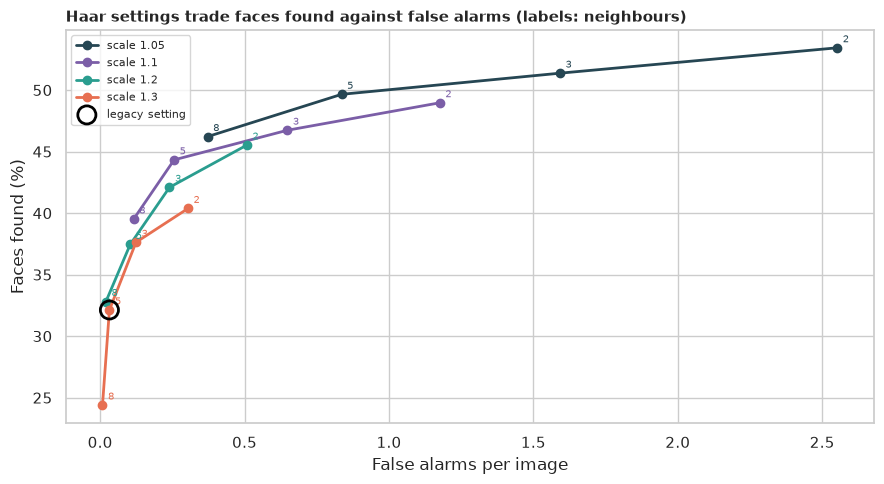

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for scale, color in zip((1.05, 1.1, 1.2, 1.3), [NAVY, PURPLE, TEAL, ORANGE], strict=True):
    sub = tune.loc[scale].sort_index()
    ax.plot(
        sub["false alarms per image"],
        sub["recall"] * 100,
        marker="o",
        color=color,
        lw=2,
        label=f"scale {scale}",
    )
    for neigh, row in sub.iterrows():
        ax.annotate(
            str(neigh),
            (row["false alarms per image"], row["recall"] * 100),
            textcoords="offset points",
            xytext=(4, 4),
            fontsize=7,
            color=color,
        )
ax.scatter(
    tune.loc[(1.3, 5), "false alarms per image"],
    tune.loc[(1.3, 5), "recall"] * 100,
    s=170,
    facecolor="none",
    edgecolor="black",
    lw=2,
    zorder=3,
    label="legacy setting",
)
ax.set_xlabel("False alarms per image")
ax.set_ylabel("Faces found (%)")
ax.set_title(
    "Haar settings trade faces found against false alarms (labels: neighbours)",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_haar_settings.png", dpi=150)
plt.show()

**How to read this:**

- **There is a clear trade-off.** More sensitive settings (smaller scale, fewer neighbours) find more faces and raise false alarms: scale 1.05 with 2 neighbours finds 53.4% of faces on the tuning half but with 2.55 false alarms per image, while scale 1.3 with 8 neighbours finds only 24.4% with almost none.
- **The best F1 on the tuning half is scale 1.05 with 8 neighbours.** On the untouched holdout half it finds **49.5%** of the faces against **34.2%** for the legacy setting, with **0.49** false alarms per image against **0.05**; F1 rises from **0.502** to **0.595**. So tuning helps, **at the price of ten times as many false alarms.**
- **Over all 500 images** the tuned setting finds **47.8%** (45.0% to 50.7%) against 33.2%, and it finds **170** faces the legacy misses while losing **1** (exact McNemar p = 1e-49). **We reject H₀**, with the caveat that half of those images were used to pick the setting; the holdout numbers above are the fair ones.
- **Even the best Haar setting stays below half.** The curves in the figure show that no setting gets Haar anywhere near a modern detector.

## 8. H3: how do modern detectors compare?

*What:* score YuNet (threshold 0.6) and BlazeFace (threshold 0.5) on the same 1,152 faces, and compare each with the legacy Haar with an exact McNemar test. The figure also sweeps their score threshold to draw the full recall-against-false-alarms curve, next to the 16 Haar settings. *Why:* a rate on its own says nothing about whether another method is better; the same faces, side by side, do.

In [7]:
yunet_cache = {id(item): detect_yunet(item["image"]) for item in dataset}
blaze_cache = {id(item): detect_blaze(item["image"]) for item in dataset}
haar_tuned_cache = {id(item): detect_haar(item["image"], *best_setting) for item in dataset}
haar_legacy_cache = {id(item): detect_haar(item["image"], 1.3, 5) for item in dataset}


def curve(cache: dict, thresholds: np.ndarray) -> pd.DataFrame:
    """Recall and false alarms per image as the score threshold is raised.

    Args:
        cache: Detections per image (keyed by ``id(item)``).
        thresholds: Score cut-offs to try.

    Returns:
        One row per threshold.
    """
    rows = []
    for t in thresholds:
        flags, fa, n_det = [], 0, 0
        for item in dataset:
            d = cache[id(item)]
            d = d[d[:, 4] >= t]
            f, a = score_detections(d, item)
            flags.append(f)
            fa += a
            n_det += len(d)
        found = np.concatenate(flags)
        rows.append(
            {
                "threshold": t,
                "recall": found.mean(),
                "false alarms per image": fa / len(dataset),
                "precision": (n_det - fa) / max(n_det, 1),
            }
        )
    return pd.DataFrame(rows)


curves = {
    "YuNet": curve(yunet_cache, np.linspace(0.1, 0.95, 12)),
    "BlazeFace": curve(blaze_cache, np.linspace(0.1, 0.95, 12)),
}
defaults = {
    "Haar, legacy settings": (haar_legacy_cache, -np.inf),
    "Haar, tuned settings": (haar_tuned_cache, -np.inf),
    "YuNet at 0.6": (yunet_cache, 0.6),
    "BlazeFace at 0.5": (blaze_cache, 0.5),
}
rows, flag_sets = [], {}
for name, (cache, t) in defaults.items():
    flags, fa, n_det = [], 0, 0
    for item in dataset:
        d = cache[id(item)]
        d = d[d[:, 4] >= t]
        f, a = score_detections(d, item)
        flags.append(f)
        fa += a
        n_det += len(d)
    found = np.concatenate(flags)
    flag_sets[name] = found
    share, low, high = wilson(int(found.sum()), len(found))
    rows.append(
        {
            "detector": name,
            "faces found": share,
            "ci_low": low,
            "ci_high": high,
            "false alarms per image": fa / len(dataset),
            "precision": (n_det - fa) / max(n_det, 1),
        }
    )
compare = pd.DataFrame(rows).set_index("detector")
print(compare.round(3).to_string())
base = flag_sets["Haar, legacy settings"]
for name in ("Haar, tuned settings", "YuNet at 0.6", "BlazeFace at 0.5"):
    ok = flag_sets[name]
    mc = mcnemar(
        [
            [int((ok & base).sum()), int((ok & ~base).sum())],
            [int((~ok & base).sum()), int((~ok & ~base).sum())],
        ],
        exact=True,
    )
    print(
        f"{name} vs legacy Haar: finds {int((ok & ~base).sum())} faces legacy misses, misses "
        f"{int((~ok & base).sum())} it finds; exact McNemar p = {fmt_p(mc.pvalue)}"
    )

                       faces found  ci_low  ci_high  false alarms per image  precision
detector                                                                              
Haar, legacy settings        0.332   0.305    0.359                   0.042      0.955
Haar, tuned settings         0.478   0.450    0.507                   0.432      0.767
YuNet at 0.6                 0.905   0.886    0.920                   0.530      0.883
BlazeFace at 0.5             0.218   0.195    0.243                   0.238      0.678
Haar, tuned settings vs legacy Haar: finds 170 faces legacy misses, misses 1 it finds; exact McNemar p = 1.1e-49
YuNet at 0.6 vs legacy Haar: finds 660 faces legacy misses, misses 0 it finds; exact McNemar p = 4.2e-199
BlazeFace at 0.5 vs legacy Haar: finds 123 faces legacy misses, misses 254 it finds; exact McNemar p = 1.4e-11


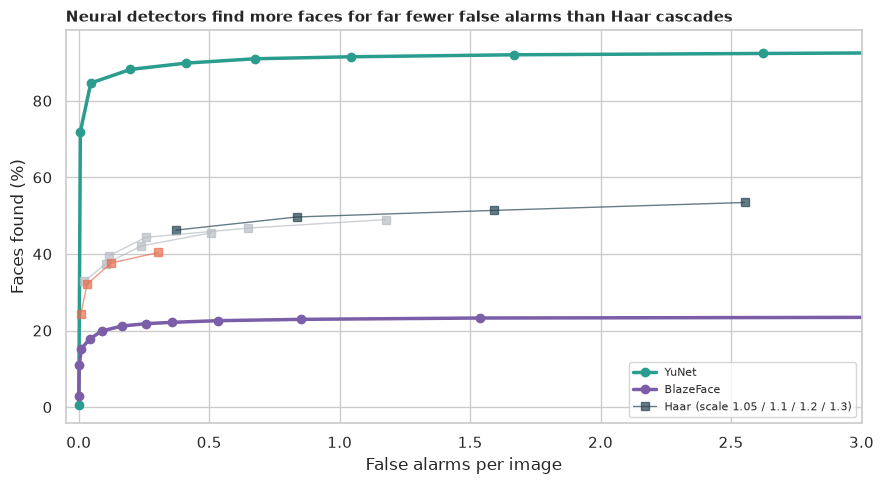

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, color in [("YuNet", TEAL), ("BlazeFace", PURPLE)]:
    sub = curves[name]
    ax.plot(
        sub["false alarms per image"],
        sub["recall"] * 100,
        marker="o",
        color=color,
        lw=2.5,
        label=name,
    )
for scale, color in zip((1.05, 1.1, 1.2, 1.3), [NAVY, GREY, GREY, ORANGE], strict=True):
    sub = tune.loc[scale].sort_index()
    ax.plot(
        sub["false alarms per image"],
        sub["recall"] * 100,
        marker="s",
        color=color,
        lw=1,
        alpha=0.7,
        label="Haar (scale 1.05 / 1.1 / 1.2 / 1.3)" if scale == 1.05 else None,
    )
ax.set_xlabel("False alarms per image")
ax.set_ylabel("Faces found (%)")
ax.set_xlim(-0.05, 3)
ax.set_title(
    "Neural detectors find more faces for far fewer false alarms than Haar cascades",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_detector_comparison.png", dpi=150)
plt.show()

**How to read this:**

- **YuNet finds nine faces in ten:** **90.5%** (95% CI 88.6% to 92.0%), against 33.2% for the legacy Haar. It finds **660** faces the legacy misses and misses **0** that the legacy finds (exact McNemar p = 4e-199). **We reject H₀.** The price is **0.53** false alarms per image (precision 88.3%), more than the legacy Haar but about the same as the tuned Haar's 0.43.
- **At a similar false-alarm level YuNet finds almost twice as many faces as the tuned Haar:** 90.5% against 47.8% (at 0.53 against 0.43 false alarms per image).
- **BlazeFace does worse than the legacy Haar here:** **21.8%** (19.5% to 24.3%); it finds 123 faces the legacy misses but misses 254 it finds (p = 1e-11, in the wrong direction). A likely reason (not tested here) is that its short-range model is built for faces filling a large part of a selfie, while the median face here is only 44 pixels tall. It is a reminder that a "modern" detector has to be matched to the job.

## 9. H4: which faces does it miss?

*What:* the legacy Haar's recall for each group of faces: blur, occlusion, pose, illumination and size band, with a chi-square test and Cramér's V (the effect size) for each factor. We then compare the faces that are clear, unoccluded and in a typical pose against all the rest, and see how YuNet does on the same two groups. *Why:* to see *why* it fails, not only how often.

In [9]:
faces_df["found"] = legacy_found
faces_df["size band"] = pd.cut(
    faces_df["size"],
    [0, 50, 80, 150, 1000],
    labels=["30-50 px", "50-80 px", "80-150 px", "over 150 px"],
)
rows = []
for col, names in {
    "blur": labels["blur"],
    "occlusion": labels["occlusion"],
    "pose": labels["pose"],
    "illumination": labels["illumination"],
    "size band": None,
}.items():
    tab = pd.crosstab(faces_df[col], faces_df["found"])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    v = float(np.sqrt(chi2 / (tab.to_numpy().sum() * (min(tab.shape) - 1))))
    parts = []
    for key in tab.index:
        sub = faces_df[faces_df[col] == key]
        label = names[int(key)] if names else str(key)
        parts.append(f"{label} {sub['found'].mean():.0%} (n={len(sub)})")
    rows.append(
        {"factor": col, "chi-square p": p, "Cramer's V": v, "recall by group": "; ".join(parts)}
    )
factor_table = pd.DataFrame(rows).set_index("factor")
pd.set_option("display.max_colwidth", 200)
print(
    factor_table.assign(
        **{
            "chi-square p": factor_table["chi-square p"].map(fmt_p),
            "Cramer's V": factor_table["Cramer's V"].round(2),
        }
    ).to_string()
)
clean_mask = (faces_df["blur"] == 0) & (faces_df["occlusion"] == 0) & (faces_df["pose"] == 0)
print(
    f"\nClear, unoccluded, typical-pose faces: {clean_mask.sum():,}; legacy Haar finds "
    f"{faces_df.loc[clean_mask, 'found'].mean():.1%}; all other faces: "
    f"{faces_df.loc[~clean_mask, 'found'].mean():.1%}"
)
yu = flag_sets["YuNet at 0.6"]
faces_df["yunet_found"] = yu
print(
    f"YuNet finds {faces_df.loc[clean_mask, 'yunet_found'].mean():.1%} of the clear faces and "
    f"{faces_df.loc[~clean_mask, 'yunet_found'].mean():.1%} of the others"
)

             chi-square p  Cramer's V                                                                            recall by group
factor                                                                                                                          
blur              2.5e-17        0.26                                     clear 42% (n=732); normal 19% (n=378); heavy 7% (n=42)
occlusion         9.1e-21        0.28                                       none 39% (n=967); partial 3% (n=87); heavy 2% (n=98)
pose              2.4e-11        0.20                                                  typical 36% (n=1045); atypical 4% (n=107)
illumination      2.2e-01        0.04                                                    normal 33% (n=1094); extreme 41% (n=58)
size band         8.0e-06        0.15  30-50 px 28% (n=701); 50-80 px 38% (n=250); 80-150 px 47% (n=143); over 150 px 43% (n=58)

Clear, unoccluded, typical-pose faces: 596; legacy Haar finds 50.5%; all other faces: 14.6%
YuNe

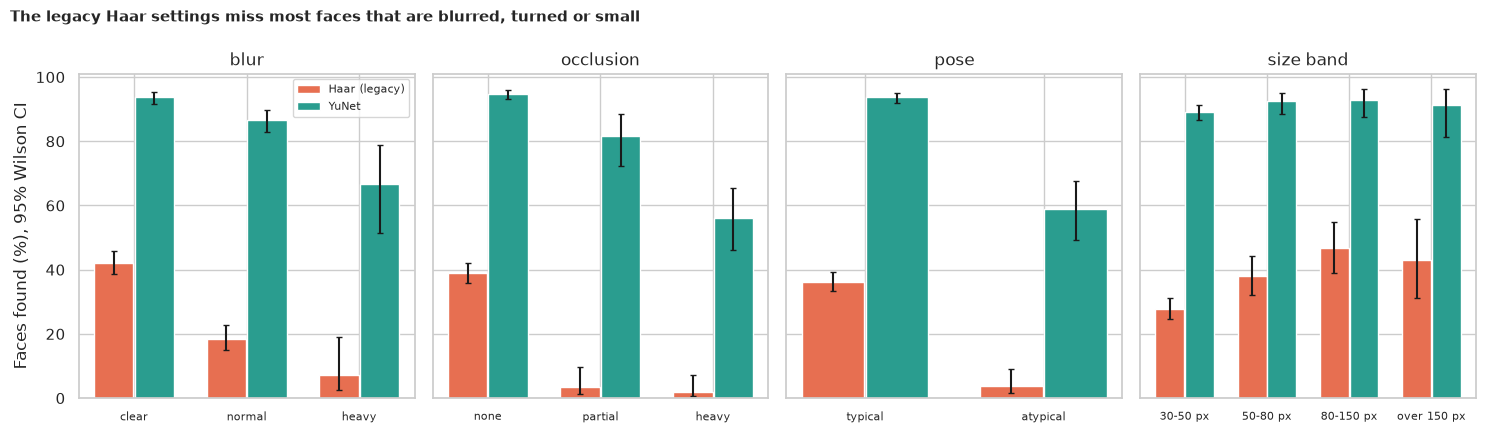

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.4), sharey=True)
for ax, col in zip(axes, ["blur", "occlusion", "pose", "size band"], strict=True):
    names = labels.get(col)
    groups = sorted(faces_df[col].dropna().unique(), key=lambda x: (str(type(x)), x))
    xs = np.arange(len(groups))
    for offset, (col_found, color, label) in zip(
        [-0.18, 0.18],
        [("found", ORANGE, "Haar (legacy)"), ("yunet_found", TEAL, "YuNet")],
        strict=True,
    ):
        shares, lows, highs = [], [], []
        for g in groups:
            sub = faces_df[faces_df[col] == g][col_found]
            s, lo, hi = wilson(int(sub.sum()), len(sub))
            shares.append(s * 100)
            lows.append((s - lo) * 100)
            highs.append((hi - s) * 100)
        ax.bar(xs + offset, shares, 0.35, color=color, yerr=[lows, highs], capsize=2, label=label)
    ax.set_xticks(xs, [names[int(g)] if names else str(g) for g in groups], fontsize=8)
    ax.set_title(col)
axes[0].set_ylabel("Faces found (%), 95% Wilson CI")
axes[0].legend(fontsize=8)
fig.suptitle(
    "The legacy Haar settings miss most faces that are blurred, turned or small",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_what_breaks_haar.png", dpi=150)
plt.show()

**How to read this:**

- **Almost every factor matters:** blur (V = 0.26), occlusion (V = 0.28), pose (V = 0.20) and size (V = 0.15) all differ significantly (p from 9e-21 to 8e-6). Illumination does not (p = 0.22, V = 0.04). **We reject H₀** for four of the five factors.
- **The cascade works on the "tutorial" face:** it finds **42%** of the clear faces (**7%** of heavily blurred ones), **39%** of the unoccluded faces (**3%** of partly and **2%** of heavily occluded), and **36%** of the typical-pose faces (**4%** of atypical ones).
- **Put the easy cases together** (clear, unoccluded, typical pose: 596 faces) and the legacy Haar finds **50.5%**; on all the other faces it finds **14.6%**.
- **Larger faces are found more often** (28% of faces 30 to 50 pixels tall, 47% of those 80 to 150), but even the large ones are missed half the time.
- **YuNet finds 98.7% of the clear faces and 81.7% of the others,** so the hard cases are hard for the classic cascade rather than impossible.

## 10. H5: what does it cost in time?

*What:* time each detector on 100 images of up to 640 pixels, on one CPU process, with a bootstrap interval for the median. *Why:* the cascade's reputation is that it is fast; the better detectors are worth little if they can't keep up with a webcam.

In [11]:
sample = [item["image"] for item in dataset[:100]]
timings = {}
for name, fn in [
    ("Haar, legacy (1.3, 5)", lambda im: detect_haar(im, 1.3, 5)),
    (
        f"Haar, tuned ({best_setting[0]}, {int(best_setting[1])})",
        lambda im: detect_haar(im, *best_setting),
    ),
    ("YuNet", detect_yunet),
    ("BlazeFace", detect_blaze),
]:
    for im in sample[:5]:
        fn(im)
    per_image = []
    for im in sample:
        t0 = time.perf_counter()
        fn(im)
        per_image.append((time.perf_counter() - t0) * 1000)
    timings[name] = np.array(per_image)
rows = []
for name, ms in timings.items():
    boot = [np.median(rng.choice(ms, len(ms))) for _ in range(N_BOOTSTRAP)]
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append(
        {
            "detector": name,
            "median ms per image": np.median(ms),
            "ci_low": low,
            "ci_high": high,
            "images per second": 1000 / np.median(ms),
        }
    )
speed = pd.DataFrame(rows).set_index("detector")
print(f"Speed on 100 images of up to {MAX_SIDE} px (one CPU process):")
print(speed.round(1).to_string())

Speed on 100 images of up to 640 px (one CPU process):
                       median ms per image  ci_low  ci_high  images per second
detector                                                                      
Haar, legacy (1.3, 5)                 14.6    13.5     15.6               68.7
Haar, tuned (1.05, 8)                 60.5    57.5     67.3               16.5
YuNet                                 31.6    30.4     33.8               31.6
BlazeFace                             11.2    11.1     11.6               89.2


**How to read this:**

- **The legacy Haar is fast, but not the fastest:** **14.6 ms** per image (about 69 images per second), against **11.2 ms** for BlazeFace (89 per second) and **31.6 ms** for YuNet (32 per second).
- **The tuned Haar is the slowest:** **60.5 ms** (about 17 per second), four times its legacy setting, because scale 1.05 examines many more image sizes. Against the tuned Haar, YuNet is **twice as fast and finds almost twice as many faces.**
- All of them are comfortably inside the 33 ms budget for a 30-frames-per-second webcam except the tuned Haar.

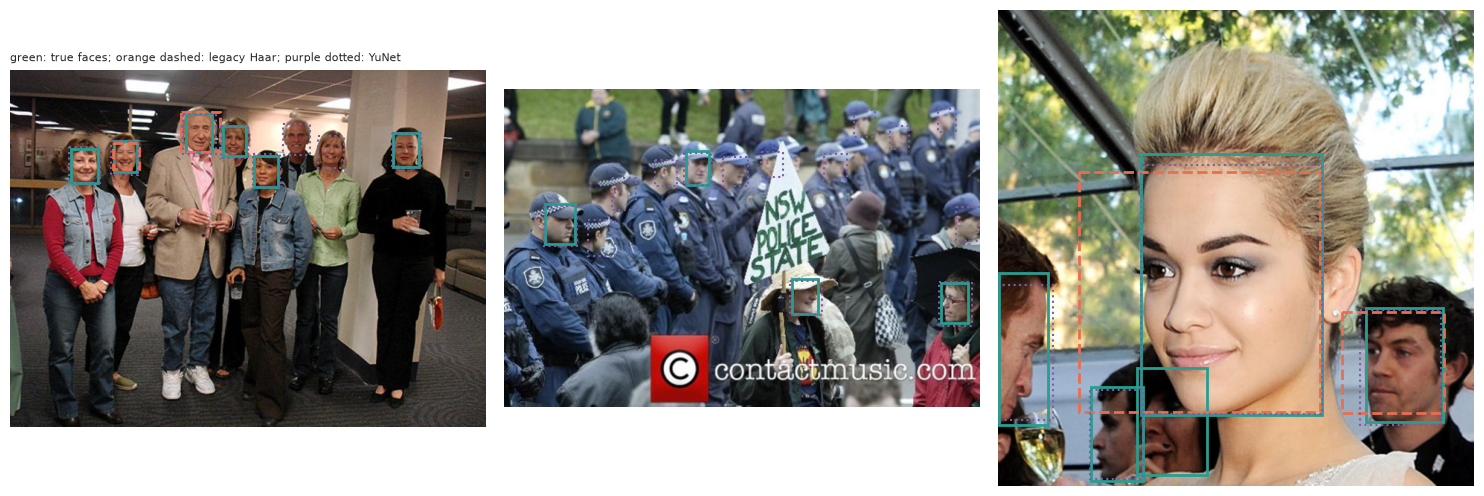

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
picks = []
for item in dataset:
    n = len(item["scored"])
    if 3 <= n <= 8 and len(picks) < 3:
        picks.append(item)
for ax, item in zip(axes, picks, strict=False):
    image = cv2.cvtColor(item["image"], cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    for f in item["scored"]:
        x, y, w, h = f["box"]
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color=TEAL, lw=2))
    for d in haar_legacy_cache[id(item)]:
        ax.add_patch(
            plt.Rectangle((d[0], d[1]), d[2], d[3], fill=False, color=ORANGE, lw=2, ls="--")
        )
    for d in yunet_cache[id(item)]:
        if d[4] >= 0.6:
            ax.add_patch(
                plt.Rectangle(
                    (d[0] - 3, d[1] - 3),
                    d[2] + 6,
                    d[3] + 6,
                    fill=False,
                    color=PURPLE,
                    lw=1.5,
                    ls=":",
                )
            )
    ax.axis("off")
axes[0].set_title(
    "green: true faces; orange dashed: legacy Haar; purple dotted: YuNet", fontsize=8, loc="left"
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_examples.png", dpi=120)
plt.show()

## 11. 🎯 Takeaways

1. **The tutorial setting finds a third of the faces** (33.2%, CI 30.5% to 35.9%) in everyday photographs, but nearly all its detections are real faces (precision 95.5%).
2. **Tuning two numbers helps, at a price:** on held-out images the best setting finds 49.5% instead of 34.2%, with ten times the false alarms and four times the run time.
3. **A modern detector is in another league:** YuNet finds 90.5% of the faces, 660 that the legacy misses against 0 the other way, and is twice as fast as the tuned cascade.
4. **A "modern" model must match the job:** BlazeFace, built for selfies, finds only 21.8% of these small faces.
5. **The cascade fails where the world is messy:** blur, occlusion, an unusual pose and small size cut its recall to between 2% and 7% (blur, occlusion), while it finds about half of the clear, unoccluded, front-facing faces.
6. **A webcam demo shows the easy case:** a person looking at the camera, close, in good light is exactly where Haar works.

## 12. ⚠️ Limitations

- **500 images, shrunk to 640 pixels.** Shrinking makes faces smaller and hurts every detector; scores at the original resolution would be higher.
- **Faces under 30 pixels are ignored,** and a few hundred hard faces would lower every score if they were counted.
- **Eyes are not tested:** WIDER FACE has no eye boxes, so the "eye detection" half of the legacy idea is not measured.
- **The IoU ≥ 0.5 rule and the thresholds (0.6 and 0.5) are choices.** The recall-against-false-alarm curves show how results move with them.
- **Tuned-Haar numbers over all 500 images are partly in-sample;** the holdout numbers (49.5% recall, 0.49 false alarms per image) are the fair ones.
- **The H4 groups overlap** (blurry faces are often small and occluded too), so each factor's effect is not isolated.
- **Speed was measured on one CPU process** and will differ on other machines.
- **Detectors were used as shipped.** None was trained or fine-tuned here, and no fairness check across skin tones, ages or genders was run; detection rates may differ across groups.